In [35]:
import numpy as np
import pandas as pd

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

In [38]:
from sklearn.model_selection import train_test_split
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
from sklearn.metrics import confusion_matrix,classification_report

In [39]:
df=pd.read_csv('Road.csv')

In [40]:
print(df.head())
print(df.info())

       Time Day_of_week Age_band_of_driver Sex_of_driver   Educational_level  \
0  17:02:00      Monday              18-30          Male   Above high school   
1  17:02:00      Monday              31-50          Male  Junior high school   
2  17:02:00      Monday              18-30          Male  Junior high school   
3   1:06:00      Sunday              18-30          Male  Junior high school   
4   1:06:00      Sunday              18-30          Male  Junior high school   

  Vehicle_driver_relation Driving_experience      Type_of_vehicle  \
0                Employee              1-2yr           Automobile   
1                Employee         Above 10yr  Public (> 45 seats)   
2                Employee              1-2yr      Lorry (41?100Q)   
3                Employee             5-10yr  Public (> 45 seats)   
4                Employee              2-5yr                  NaN   

  Owner_of_vehicle Service_year_of_vehicle  ... Vehicle_movement  \
0            Owner              Abov

In [41]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include='object').columns

In [42]:
imputer_num = SimpleImputer(strategy='mean')
df[num_cols] = imputer_num.fit_transform(df[num_cols])

In [43]:
imputer_cat = SimpleImputer(strategy='most_frequent')
df[cat_cols] = imputer_cat.fit_transform(df[cat_cols])

In [44]:
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

In [45]:
X = df.drop('Accident_severity', axis=1)
y = df['Accident_severity']

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,stratify=y)

In [47]:
model = BalancedRandomForestClassifier(
    n_estimators=400,
    max_depth=10,
    random_state=42
)

In [48]:
model.fit(X_train, y_train)

,n_estimators,400
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [52]:
model.score(X_train,y_train)

0.7159967519285424

In [53]:
y_pred = model.predict(X_test)

In [54]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.640422077922078
Precision: 0.7709629235853861
Recall: 0.640422077922078
F1 Score: 0.6901853014095122

Confusion Matrix:
 [[  13    6   12]
 [  17  140  192]
 [ 148  511 1425]]

Classification Report:
               precision    recall  f1-score   support

           0       0.07      0.42      0.12        31
           1       0.21      0.40      0.28       349
           2       0.87      0.68      0.77      2084

    accuracy                           0.64      2464
   macro avg       0.39      0.50      0.39      2464
weighted avg       0.77      0.64      0.69      2464



In [55]:
feature_importances = pd.Series(model.feature_importances_, index=X.columns)
print(feature_importances.sort_values(ascending=False))

Number_of_casualties           0.110464
Time                           0.100595
Day_of_week                    0.056602
Cause_of_accident              0.055993
Number_of_vehicles_involved    0.049459
Type_of_vehicle                0.049323
Area_accident_occured          0.046385
Age_band_of_driver             0.043896
Driving_experience             0.041442
Lanes_or_Medians               0.037377
Types_of_Junction              0.036188
Vehicle_movement               0.035765
Service_year_of_vehicle        0.033936
Type_of_collision              0.031545
Age_band_of_casualty           0.029944
Educational_level              0.027229
Light_conditions               0.025355
Work_of_casuality              0.024486
Casualty_class                 0.022361
Sex_of_casualty                0.019801
Road_allignment                0.019246
Road_surface_conditions        0.015857
Casualty_severity              0.015682
Weather_conditions             0.015356
Vehicle_driver_relation        0.013453


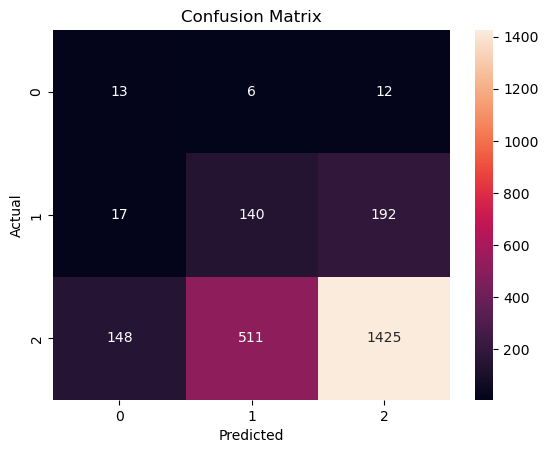

In [56]:
cm = confusion_matrix(y_test, y_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

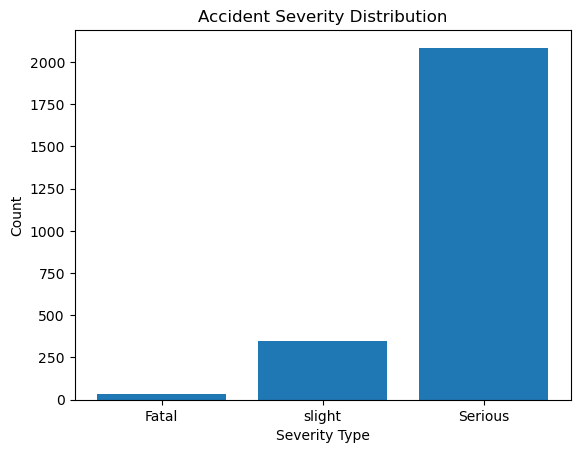

In [57]:


classes = ['Fatal', 'slight', 'Serious']
counts = [31, 349, 2084]   

plt.figure()
plt.bar(classes, counts)

plt.title('Accident Severity Distribution')
plt.xlabel('Severity Type')
plt.ylabel('Count')

plt.show()

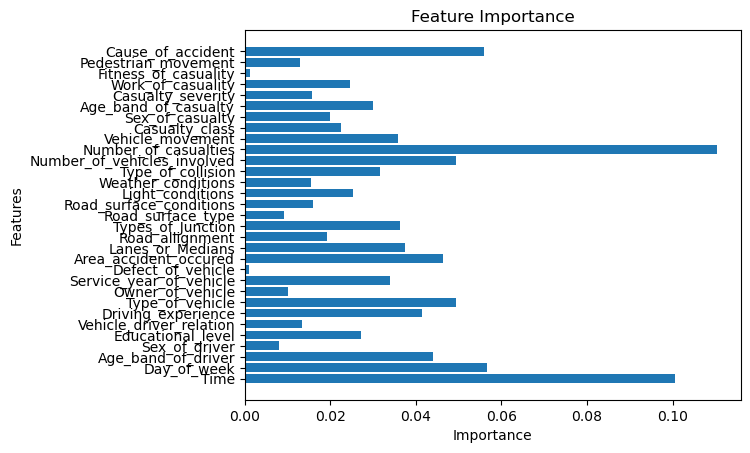

In [58]:
importances = model.feature_importances_
features = X.columns

plt.figure()
plt.barh(features, importances)

plt.title('Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')

plt.show()